In [1]:
import sys
import importlib.util

print("Python environment:", sys.executable)

packages = [
    "xarray",
    "zarr",
    "gcsfs",
    "dask",
    "pandas",
    "numpy",
    "matplotlib",
    "cftime",
]

for package in packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'installed' if installed else 'missing'}")

Python environment: /opt/anaconda3/envs/COGS108_FA25/bin/python
xarray: missing
zarr: missing
gcsfs: missing
dask: installed
pandas: installed
numpy: installed
matplotlib: installed
cftime: missing


In [2]:
%pip install xarray zarr gcsfs cftime

  Using cached pyasn1_modules-0.4.2-py3-none-any.whl.metadata (3.5 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 32.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 543.8/543.8 kB 38.0 MB/s  0:00:00
Using cached requests-2.34.2-py3-none-any.whl (73 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 4.9 MB/s  0:00:00
Using cached pyasn1_modules-0.4.2-py3-none-any.whl (181 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 4.4 MB/s  0:00:024.5 MB/s eta 0:00:0102
  Attempting uninstall: requests
    Found existing installation: requests 2.32.5
    Uninstalling requests-2.32.5:
      Successfully uninstalled requests-2.32.5
  Attempting uninstall: protobuf
    Found existing installation: protobuf 6.31.1
    Uninstalling protobuf-6.31.1:
      Successfully uninstalled protobuf-6.31.1
  Attempting uninstall: fsspec0m╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  5/26 [grpcio]
    Found existing i

In [1]:
import pandas as pd
import xarray as xr

catalog_url = (
    "https://storage.googleapis.com/cmip6/"
    "cmip6-zarr-consolidated-stores.csv"
)

catalog = pd.read_csv(catalog_url)

# Find monthly temperature data for our model and experiments.
selection = catalog[
    (catalog["source_id"] == "ACCESS-CM2")
    & (catalog["member_id"] == "r1i1p1f1")
    & (catalog["table_id"] == "Amon")
    & (catalog["variable_id"] == "tas")
    & (catalog["grid_label"] == "gn")
    & (catalog["experiment_id"].isin(["historical", "ssp245"]))
]

display(selection[["experiment_id", "variable_id", "zstore"]])

,experiment_id,variable_id,zstore
378865,ssp245,tas,gs://cmip6/CMIP6/ScenarioMIP/CSIRO-ARCCSS/ACCE...
378954,historical,tas,gs://cmip6/CMIP6/CMIP/CSIRO-ARCCSS/ACCESS-CM2/...


In [2]:
import gcsfs

# Anonymous access to the public Google Cloud bucket.
fs = gcsfs.GCSFileSystem(token="anon")

datasets = {}

for experiment in ["historical", "ssp245"]:
    path = selection.loc[
        selection["experiment_id"] == experiment, "zstore"
    ].iloc[0]

    datasets[experiment] = xr.open_zarr(
        fs.get_mapper(path),
        consolidated=True,
        chunks="auto",
    )

    ds = datasets[experiment]

    print(f"\n{experiment.upper()}")
    print("Temperature dimensions:", dict(ds["tas"].sizes))
    print("Units:", ds["tas"].attrs.get("units"))
    print("First date:", str(ds["time"].values[0]))
    print("Last date:", str(ds["time"].values[-1]))
    print("Latitude range:", float(ds.lat.min()), "to", float(ds.lat.max()))
    print("Longitude range:", float(ds.lon.min()), "to", float(ds.lon.max()))

I1112 18:07:20.931226 13570352 fork_posix.cc:71] Other threads are currently calling into gRPC, skipping fork() handlers
I1112 18:07:20.941537 13570423 ev_poll_posix.cc:588] FD from fork parent still in poll list: fd(88, generation: 1)



HISTORICAL
Temperature dimensions: {'time': 1980, 'lat': 144, 'lon': 192}
Units: K
First date: 1850-01-16T12:00:00.000000000
Last date: 2014-12-16T12:00:00.000000000
Latitude range: -89.375 to 89.375
Longitude range: 0.9375 to 359.0625

SSP245
Temperature dimensions: {'time': 1032, 'lat': 144, 'lon': 192}
Units: K
First date: 2015-01-16T12:00:00.000000000
Last date: 2100-12-16T12:00:00.000000000
Latitude range: -89.375 to 89.375
Longitude range: 0.9375 to 359.0625


In [3]:
# Select the two 20-year periods.
historical = datasets["historical"]["tas"].sel(
    time=slice("1995-01-01", "2014-12-31")
)

future = datasets["ssp245"]["tas"].sel(
    time=slice("2081-01-01", "2100-12-31")
)

# Weight monthly averages by the number of days in each month.
historical_mean = historical.weighted(
    historical.time.dt.days_in_month
).mean("time")

future_mean = future.weighted(
    future.time.dt.days_in_month
).mean("time")

# Download the required data and calculate warming at each grid cell.
warming = (future_mean - historical_mean).compute()

# A temperature difference in Kelvin equals the difference in Celsius.
warming.name = "Projected warming"
warming.attrs["units"] = "°C"

print("Map dimensions:", dict(warming.sizes))
print(f"Smallest grid-cell warming: {warming.min().item():.2f} °C")
print(f"Largest grid-cell warming: {warming.max().item():.2f} °C")

Map dimensions: {'lat': 144, 'lon': 192}
Smallest grid-cell warming: 0.71 °C
Largest grid-cell warming: 11.05 °C


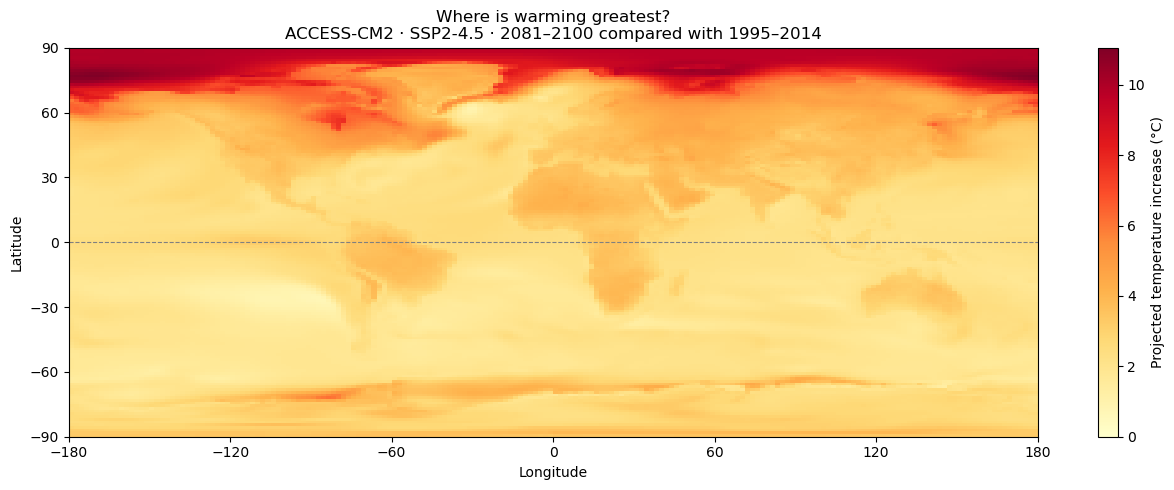

In [4]:
import matplotlib.pyplot as plt

# Convert longitude from 0–360° to −180–180° for easier reading.
warming_map = warming.assign_coords(
    lon=((warming.lon + 180) % 360) - 180
).sortby("lon")

fig, ax = plt.subplots(figsize=(13, 5))

warming_map.plot.pcolormesh(
    ax=ax,
    x="lon",
    y="lat",
    cmap="YlOrRd",
    vmin=0,
    cbar_kwargs={"label": "Projected temperature increase (°C)"},
)

ax.set_title(
    "Where is warming greatest?\n"
    "ACCESS-CM2 · SSP2-4.5 · 2081–2100 compared with 1995–2014"
)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_xticks([-180, -120, -60, 0, 60, 120, 180])
ax.set_yticks([-90, -60, -30, 0, 30, 60, 90])
ax.axhline(0, color="gray", linewidth=0.8, linestyle="--")

plt.tight_layout()
plt.show()

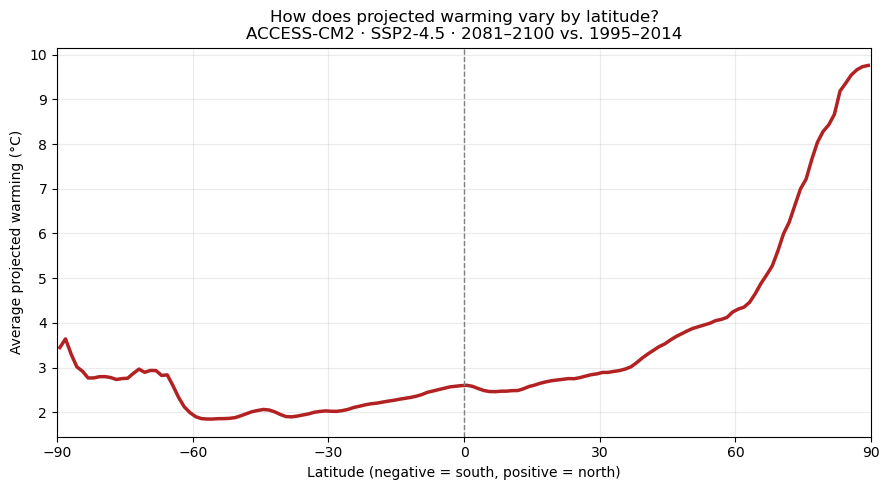

In [5]:
# Average across all longitudes at each latitude.
# Cells in each latitude row have equal area on this regular grid.
latitude_warming = warming.mean(dim="lon")

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    latitude_warming["lat"],
    latitude_warming,
    color="firebrick",
    linewidth=2.5,
)

ax.axvline(0, color="gray", linestyle="--", linewidth=1)
ax.set(
    title=(
        "How does projected warming vary by latitude?\n"
        "ACCESS-CM2 · SSP2-4.5 · 2081–2100 vs. 1995–2014"
    ),
    xlabel="Latitude (negative = south, positive = north)",
    ylabel="Average projected warming (°C)",
    xlim=(-90, 90),
)
ax.set_xticks([-90, -60, -30, 0, 30, 60, 90])
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

/opt/anaconda3/envs/COGS108_FA25/lib/python3.11/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/opt/anaconda3/envs/COGS108_FA25/lib/python3.11/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/opt/anaconda3/envs/COGS108_FA25/lib/python3.11/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_1_states_provinces_lakes.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


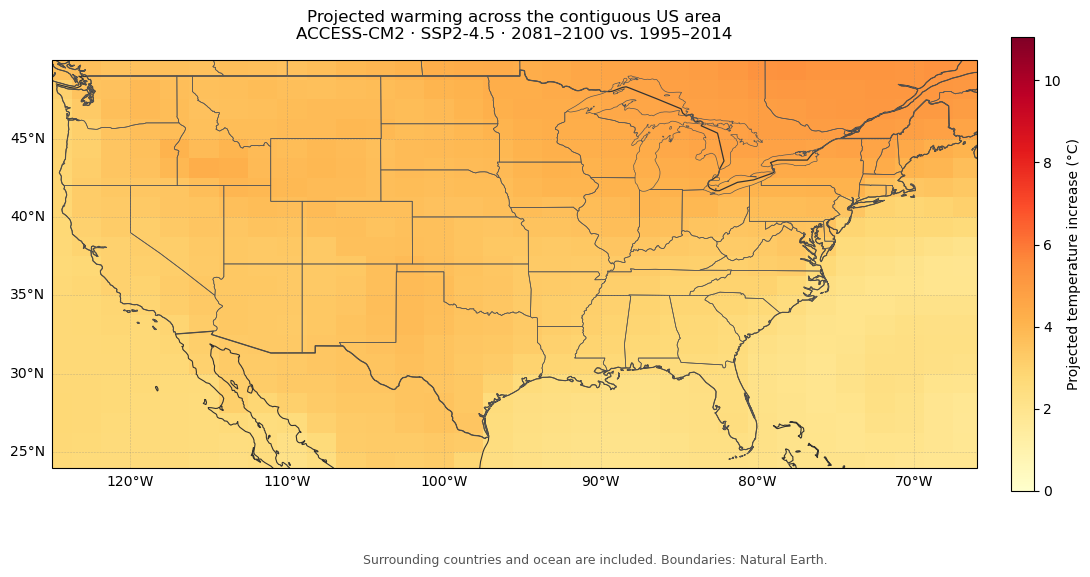

In [11]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Convert longitude to −180–180°.
warming_map = warming.assign_coords(
    lon=((warming.lon + 180) % 360) - 180
).sortby("lon")

us_window = warming_map.sel(
    lon=slice(-125, -66),
    lat=slice(24, 50),
)

fig, ax = plt.subplots(
    figsize=(12, 6),
    subplot_kw={"projection": ccrs.PlateCarree()},
)

# Keep the same color scale as our global map.
mesh = ax.pcolormesh(
    us_window.lon,
    us_window.lat,
    us_window,
    transform=ccrs.PlateCarree(),
    cmap="YlOrRd",
    vmin=0,
    vmax=float(warming.max()),
    shading="auto",
)

ax.set_extent([-125, -66, 24, 50], crs=ccrs.PlateCarree())

# Overlay geographic boundaries.
ax.coastlines(resolution="50m", linewidth=0.8, color="#333333")
ax.add_feature(
    cfeature.BORDERS.with_scale("50m"),
    linewidth=0.9,
    edgecolor="#333333",
)
ax.add_feature(
    cfeature.STATES.with_scale("50m"),
    linewidth=0.5,
    edgecolor="#555555",
    facecolor="none",
)

grid = ax.gridlines(
    draw_labels=True,
    linewidth=0.4,
    color="gray",
    alpha=0.4,
    linestyle="--",
)
grid.top_labels = False
grid.right_labels = False

fig.colorbar(
    mesh,
    ax=ax,
    pad=0.03,
    shrink=0.85,
    label="Projected temperature increase (°C)",
)

ax.set_title(
    "Projected warming across the contiguous US area\n"
    "ACCESS-CM2 · SSP2-4.5 · 2081–2100 vs. 1995–2014",
    pad=15,
)

fig.text(
    0.5, 0.03,
    "Surrounding countries and ocean are included. "
    "Boundaries: Natural Earth.",
    ha="center",
    fontsize=9,
    color="#555555",
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

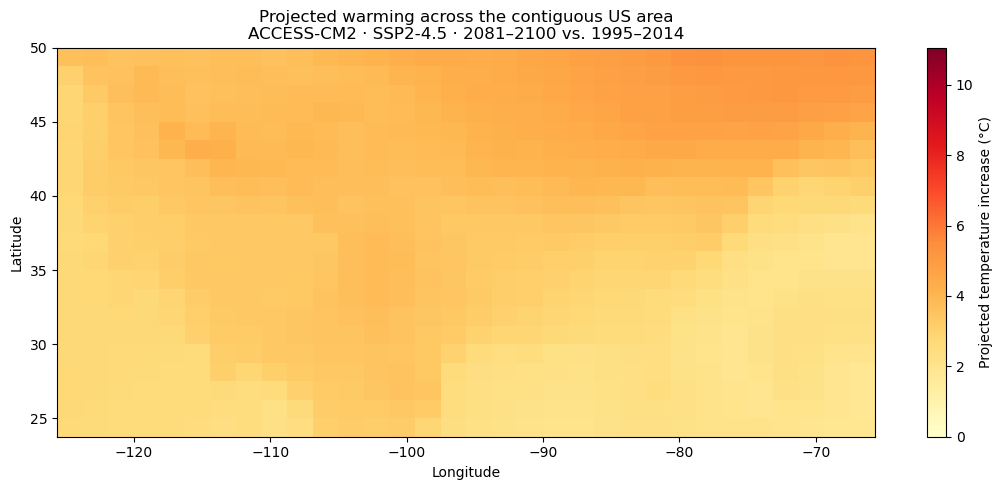

In [6]:
# Geographic window around the contiguous US.
# This rectangle also includes nearby ocean, Canada, and Mexico.
us_window = warming_map.sel(
    lon=slice(-125, -66),
    lat=slice(24, 50),
)

fig, ax = plt.subplots(figsize=(11, 5))

us_window.plot.pcolormesh(
    ax=ax,
    x="lon",
    y="lat",
    cmap="YlOrRd",
    vmin=0,
    vmax=float(warming.max()),
    cbar_kwargs={"label": "Projected temperature increase (°C)"},
)

ax.set_title(
    "Projected warming across the contiguous US area\n"
    "ACCESS-CM2 · SSP2-4.5 · 2081–2100 vs. 1995–2014"
)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

Area-weighted global warming: 2.80 °C


,Latitude band,Warming (°C),Ratio to global average
0,90°S–60°S,2.68,0.96
1,60°S–30°S,1.95,0.70
2,30°S–0°,2.30,0.82
3,0°–30°N,2.62,0.94
4,30°N–60°N,3.46,1.24
5,60°N–90°N,6.01,2.14


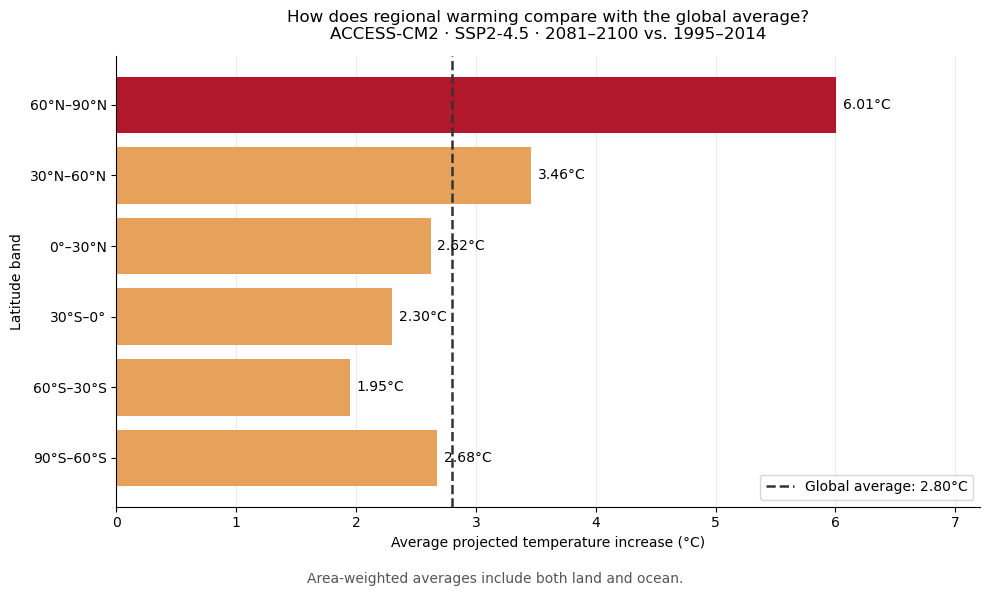

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Area weights for this regular latitude–longitude grid.
weights = np.cos(np.deg2rad(warming["lat"]))

global_average = warming.weighted(weights).mean(
    dim=["lat", "lon"]
).item()

# Non-overlapping bands, ordered from south to north.
bands = [
    ("90°S–60°S", -90, -60),
    ("60°S–30°S", -60, -30),
    ("30°S–0°", -30, 0),
    ("0°–30°N", 0, 30),
    ("30°N–60°N", 30, 60),
    ("60°N–90°N", 60, 90),
]

results = []

for label, lower, upper in bands:
    region = warming.where(
        (warming["lat"] >= lower) & (warming["lat"] < upper),
        drop=True,
    )

    region_weights = np.cos(np.deg2rad(region["lat"]))

    regional_average = region.weighted(region_weights).mean(
        dim=["lat", "lon"]
    ).item()

    results.append({
        "Latitude band": label,
        "Warming (°C)": regional_average,
        "Ratio to global average": regional_average / global_average,
    })

band_summary = pd.DataFrame(results)

print(f"Area-weighted global warming: {global_average:.2f} °C")
display(band_summary.round(2))

# Plot regional averages with a global reference line.
fig, ax = plt.subplots(figsize=(10, 6))

colors = ["#e6a15a"] * 5 + ["#b2182b"]

bars = ax.barh(
    band_summary["Latitude band"],
    band_summary["Warming (°C)"],
    color=colors,
)

ax.bar_label(bars, fmt="%.2f°C", padding=5)

ax.axvline(
    global_average,
    color="#333333",
    linestyle="--",
    linewidth=1.8,
    label=f"Global average: {global_average:.2f}°C",
)

ax.set_xlim(0, band_summary["Warming (°C)"].max() * 1.2)
ax.set_xlabel("Average projected temperature increase (°C)")
ax.set_ylabel("Latitude band")
ax.set_title(
    "How does regional warming compare with the global average?\n"
    "ACCESS-CM2 · SSP2-4.5 · 2081–2100 vs. 1995–2014",
    pad=12,
)

ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right")

fig.text(
    0.5, 0.02,
    "Area-weighted averages include both land and ocean.",
    ha="center",
    fontsize=10,
    color="#555555",
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

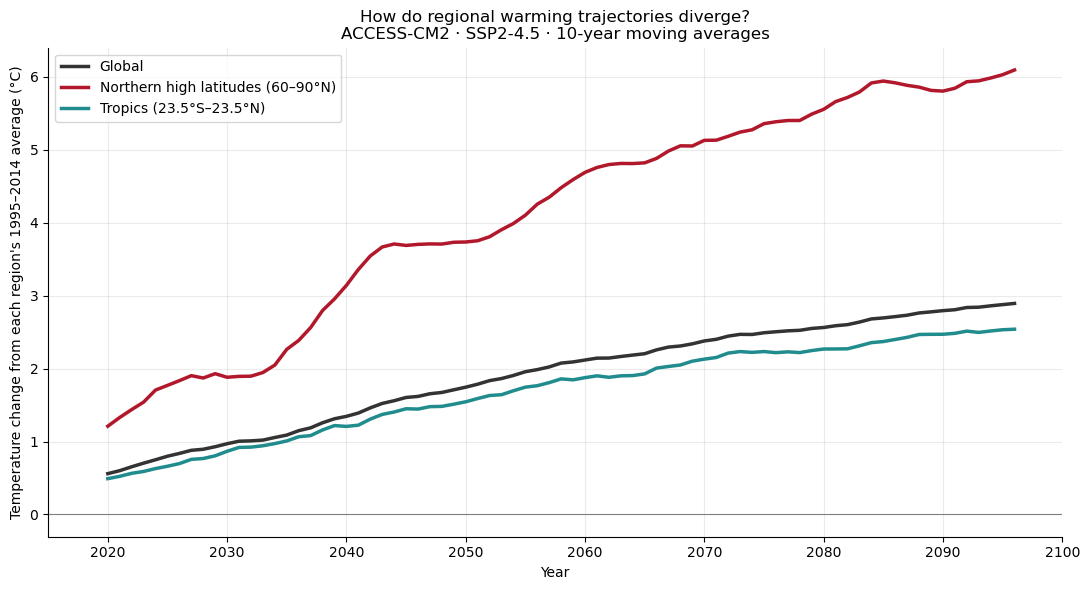

In [8]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

regions = {
    "Global": (-90, 90),
    "Northern high latitudes (60–90°N)": (60, 90),
    "Tropics (23.5°S–23.5°N)": (-23.5, 23.5),
}

def regional_monthly_mean(data, lower, upper):
    subset = data.where(
        (data.lat >= lower) & (data.lat <= upper),
        drop=True,
    )
    weights = np.cos(np.deg2rad(subset.lat))
    return subset.weighted(weights).mean(dim=["lat", "lon"])

baseline_data = datasets["historical"]["tas"].sel(
    time=slice("1995-01-01", "2014-12-31")
)

projection_data = datasets["ssp245"]["tas"].sel(
    time=slice("2015-01-01", "2100-12-31")
)

series = {}

for label, (lower, upper) in regions.items():
    historical_monthly = regional_monthly_mean(
        baseline_data, lower, upper
    )
    future_monthly = regional_monthly_mean(
        projection_data, lower, upper
    )

    # Each region's own historical average, weighted by month length.
    baseline = historical_monthly.weighted(
        historical_monthly.time.dt.days_in_month
    ).mean("time")

    # Annual means, also weighted by month length.
    days = future_monthly.time.dt.days_in_month

    annual_mean = (
        (future_monthly * days).groupby("time.year").sum("time")
        / days.groupby("time.year").sum("time")
    )

    series[label] = annual_mean - baseline

# Compute all three series together.
annual_warming = xr.Dataset(series).compute()

# Smooth annual variability using complete 10-year windows.
smoothed_warming = annual_warming.rolling(
    year=10, center=True, min_periods=10
).mean()

fig, ax = plt.subplots(figsize=(11, 6))

colors = {
    "Global": "#333333",
    "Northern high latitudes (60–90°N)": "#b2182b",
    "Tropics (23.5°S–23.5°N)": "#218c8d",
}

for label, color in colors.items():
    ax.plot(
        smoothed_warming.year,
        smoothed_warming[label],
        label=label,
        color=color,
        linewidth=2.5,
    )

ax.axhline(0, color="gray", linewidth=0.8)
ax.set(
    title=(
        "How do regional warming trajectories diverge?\n"
        "ACCESS-CM2 · SSP2-4.5 · 10-year moving averages"
    ),
    xlabel="Year",
    ylabel="Temperature change from each region's 1995–2014 average (°C)",
    xlim=(2015, 2100),
)
ax.grid(alpha=0.25)
ax.legend()
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

season,Dec–Feb,Mar–May,Jun–Aug,Sep–Nov
latitude_band,,,,
60°N–90°N,9.24,4.58,3.23,7.03
30°N–60°N,3.48,2.90,3.78,3.68
0°–30°N,2.64,2.59,2.63,2.63
30°S–0°,2.28,2.35,2.30,2.28
60°S–30°S,1.99,2.04,1.90,1.86
90°S–60°S,2.08,2.72,3.74,2.16


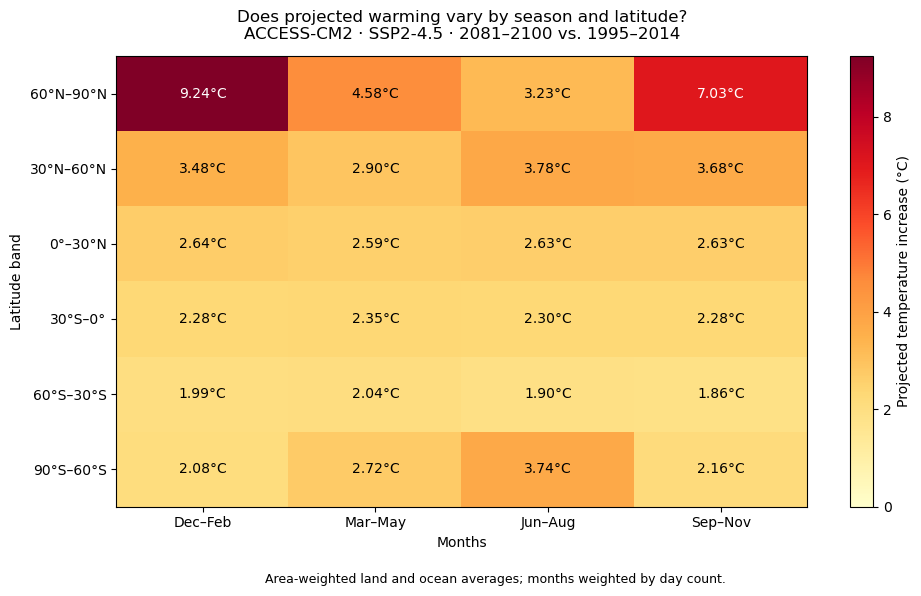

In [9]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

# Use month labels because seasons differ between hemispheres.
season_months = {
    "Dec–Feb": [12, 1, 2],
    "Mar–May": [3, 4, 5],
    "Jun–Aug": [6, 7, 8],
    "Sep–Nov": [9, 10, 11],
}

latitude_bands = [
    ("60°N–90°N", 60, 90),
    ("30°N–60°N", 30, 60),
    ("0°–30°N", 0, 30),
    ("30°S–0°", -30, 0),
    ("60°S–30°S", -60, -30),
    ("90°S–60°S", -90, -60),
]

historical_period = datasets["historical"]["tas"].sel(
    time=slice("1995-01-01", "2014-12-31")
)
future_period = datasets["ssp245"]["tas"].sel(
    time=slice("2081-01-01", "2100-12-31")
)

def seasonal_average(monthly_series, months):
    selected = monthly_series.where(
        monthly_series.time.dt.month.isin(months),
        drop=True,
    )
    return selected.weighted(
        selected.time.dt.days_in_month
    ).mean("time")

band_results = []

for label, lower, upper in latitude_bands:
    regional_series = []

    for period in [historical_period, future_period]:
        subset = period.where(
            (period.lat >= lower) & (period.lat < upper),
            drop=True,
        )
        weights = np.cos(np.deg2rad(subset.lat))

        regional_series.append(
            subset.weighted(weights).mean(dim=["lat", "lon"])
        )

    historical_monthly, future_monthly = regional_series

    seasonal_changes = [
        seasonal_average(future_monthly, months)
        - seasonal_average(historical_monthly, months)
        for months in season_months.values()
    ]

    band_results.append(
        xr.concat(
            seasonal_changes,
            dim=pd.Index(list(season_months), name="season"),
        )
    )

seasonal_warming = xr.concat(
    band_results,
    dim=pd.Index(
        [band[0] for band in latitude_bands],
        name="latitude_band",
    ),
).compute()

display(seasonal_warming.to_pandas().round(2))

# Heatmap with a common scale across every band and season.
values = seasonal_warming.values
vmax = max(0.1, float(np.nanmax(np.abs(values))))
has_cooling = bool(np.nanmin(values) < 0)

fig, ax = plt.subplots(figsize=(10, 6))

heatmap = ax.imshow(
    values,
    cmap="RdBu_r" if has_cooling else "YlOrRd",
    vmin=-vmax if has_cooling else 0,
    vmax=vmax,
    aspect="auto",
)

ax.set_xticks(range(len(season_months)))
ax.set_xticklabels(list(season_months))
ax.set_yticks(range(len(latitude_bands)))
ax.set_yticklabels([band[0] for band in latitude_bands])

for row in range(values.shape[0]):
    for col in range(values.shape[1]):
        value = values[row, col]
        rgba = heatmap.cmap(heatmap.norm(value))
        brightness = (
            0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
        )
        ax.text(
            col, row, f"{value:.2f}°C",
            ha="center", va="center",
            color="black" if brightness > 0.55 else "white",
        )

fig.colorbar(
    heatmap, ax=ax,
    label="Projected temperature increase (°C)",
)

ax.set_title(
    "Does projected warming vary by season and latitude?\n"
    "ACCESS-CM2 · SSP2-4.5 · 2081–2100 vs. 1995–2014",
    pad=12,
)
ax.set_xlabel("Months")
ax.set_ylabel("Latitude band")

fig.text(
    0.5, 0.02,
    "Area-weighted land and ocean averages; months weighted by day count.",
    ha="center", fontsize=9,
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()